# Quality control of images and single cells

**Question:** which images and which cells are good enough to keep for the analysis?

**Answer: 73–89% of cells pass both checks, depending on plate and cell line.**

- **Image QC:** 193 of 10,257 images are blurred or over-exposed. They hold 1.5% of all cells. Most are over-exposed Mito images of CL1 at 24h.
- **Profile QC:** 19.7–23.4% of CL1 cells and 10.6–11.6% of CL2 cells have a bad outline. Most of these hold two or more nuclei merged into one cell.

This notebook checks the data at two levels, and adds one pass/fail column for each level:

| Level | What can go wrong | Column |
|---|---|---|
| **Image** | The image is blurred, or over-exposed (pixels at the camera's maximum) | `Metadata_image_qc` |
| **Profile** (single cell) | CellProfiler drew a wrong outline, for example two nuclei in one cell | `Metadata_profile_qc` |

At the end, the notebook joins the 3 plates into one table, the **QC profile**, with all features and both QC columns. It removes no cell from the table. Keep the cells where both columns are `pass`.

The notebook has three parts: A. image QC (sections 2–4), B. profile QC (sections 5–12), C. the QC profile (section 13).

| Term | Meaning |
|---|---|
| Site, image | One field of view in a well (9 per well), imaged in 5 channels. In this notebook, an "image" means this set of 5 channel images. Each plate has 3,420 of them (17,100 image files). |
| Object | One nucleus, with its cell, as CellProfiler found it. Ideally, one object is one cell. |
| MAD | Median absolute deviation: a measure of spread that a few extreme values do not move. |
| z-score | How far a value lies from the group average, in standard deviations. |
| G1, G2 | Cells with one set of DNA (G1), and cells that copied their DNA, with two sets (G2). |
| CL1, CL2 | The two cell lines, in columns 1–12 and 13–24. |

## Setup

Run with `_run.sbatch` (about 3 minutes).

In [1]:
import os
import pathlib
import shutil

n_threads = 8
os.environ["POLARS_MAX_THREADS"] = str(n_threads)
os.environ["OMP_NUM_THREADS"] = str(n_threads)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import duckdb
import polars as pl
import seaborn as sns
from cosmicqc import analyze
from PIL import Image
from scipy import ndimage as ndi

In [2]:
seed = 0

profiles_dir = pathlib.Path("../0.prepare-profiles/results/single-cell-profiles").resolve(strict=True)
metadata_dir = pathlib.Path("../../data/metadata").resolve(strict=True)
cellprofiler_dir = pathlib.Path("../../data/sc-profiles/PALS-screen-profiles-v2").resolve(strict=True)
images_dir = pathlib.Path("../../../../project-data/PALS-screen-data").resolve(strict=True)

# the QC profile: all plates in one table, with the QC columns added
results_dir = pathlib.Path("results").resolve()
results_dir.mkdir(parents=True, exist_ok=True)
qc_profile_path = results_dir / "qc_Panc1_hPSC_sc-profiles.parquet"

# DuckDB writes the QC profile without holding it in memory; data that does not fit spills to tmp_dir
duckdb_memory_limit = "64GB"
tmp_dir = pathlib.Path("tmp").resolve()

# image QC: a channel is blurred if its focus measure is more than 5 MADs below the other images of its
# plate and cell line, and over-exposed if more than 1% of its pixels are at the camera's maximum
channels = ["DNA", "RNA", "AGP", "ER", "Mito"]
channel_wavelength = {"DNA": 405, "RNA": 488, "AGP": 561, "Mito": 638, "ER": 730}
blur_limit = -5
saturation_limit = 1

# the 4 measurements, with the names CellProfiler uses in our tables
mass_displacement = "Nuclei_Intensity_MassDisplacement_CorrDNA"
nucleus_dna = "Nuclei_Intensity_IntegratedIntensity_CorrDNA"
nucleus_solidity = "Nuclei_AreaShape_Solidity"
cell_dna = "Cells_Intensity_IntegratedIntensity_CorrDNA"

# the rules of the paper: a positive limit marks high values, a negative limit marks low values
conditions = {
    "under_segmented_nuclei": {mass_displacement: 0.05, nucleus_dna: 1.5},
    "poorly_segmented_nuclei": {nucleus_solidity: -1.6},
    "under_segmented_cells": {cell_dna: 0.5},
}

# the same rules with the numbers printed in panel A of Figure 2
conditions_panel_a = {
    "under_segmented_nuclei": {mass_displacement: 0.05, nucleus_dna: 1.15},
    "poorly_segmented_nuclei": {nucleus_solidity: -1.16},
    "under_segmented_cells": {cell_dna: 0.5},
}

condition_names = list(conditions)

# the profile QC rule (section 12): condition 3 flags healthy G2 cells in CL2, so CL2 leaves it out
rule_conditions = {
    "CL1": ["under_segmented_nuclei", "poorly_segmented_nuclei", "under_segmented_cells"],
    "CL2": ["under_segmented_nuclei", "poorly_segmented_nuclei"],
}
# the reason for a failed profile, in plain words
condition_reasons = {
    "under_segmented_nuclei": "merged nuclei",
    "poorly_segmented_nuclei": "irregular nucleus outline",
    "under_segmented_cells": "cell outline holds other nuclei",
}
condition_titles = {
    "under_segmented_nuclei": "1. Under-segmented nuclei",
    "poorly_segmented_nuclei": "2. Poorly segmented nuclei",
    "under_segmented_cells": "3. Under-segmented cells",
}

# fixed order and colors: the same as in notebook 01
plate_order = ["1h", "4h", "24h"]
line_order = ["CL1", "CL2"]
line_colors = {"CL1": "#6250d6", "CL2": "#eda100"}
plate_colors = {"1h": "#2a78d6", "4h": "#eb6834", "24h": "#1baf7a"}
limit_color = "#e34948"
guide_color = "#52514e"



def in_time_order(table):
    """Sort a table by cell line, then by plate in time order."""
    order = pl.col("plate").replace_strict({time: i for i, time in enumerate(plate_order)}, return_dtype=pl.Int64)
    return table.sort("cell_line", order)


# figure style for print: figure sizes are the size on paper (7.2 in = full page width), text is 6-9 pt
sns.set_theme(style="ticks")
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6.5, "legend.title_fontsize": 7, "figure.titlesize": 9,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "pdf.fonttype": 42,
})
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(50)

polars.config.Config

## 1. Load the profiles

**Pass if:** every cell has a well label and the 4 measurements that coSMicQC uses.

In [3]:
plate_files = {path.stem.split("_")[3]: path for path in sorted(profiles_dir.glob("*.parquet"))}
plate_names = {time: plate_files[time].stem for time in plate_order}

columns = [
    "Metadata_Plate",
    "Metadata_Well",
    "Metadata_Site",
    "Metadata_Acquisition",
    "Metadata_ObjectNumber",
    "Nuclei_AreaShape_Area",
    "Nuclei_Location_Center_X",
    "Nuclei_Location_Center_Y",
    mass_displacement,
    nucleus_dna,
    nucleus_solidity,
    cell_dna,
]

platemap = pl.read_csv(metadata_dir / "platemap.csv", infer_schema_length=0).select(
    pl.col("Well").alias("Metadata_Well"),
    pl.col("Compound ID").alias("compound"),
)
ligands = (
    pl.read_csv(metadata_dir / "ligands.csv", infer_schema_length=0)
    .select(pl.col("destination well").alias("well"), pl.col("Treatment").alias("ligand"))
    .filter(pl.col("well").is_not_null())
    .with_columns((pl.col("well").str.slice(0, 1) + pl.col("well").str.slice(1).str.zfill(2)).alias("Metadata_Well"))
    .drop("well")
)
wells = (
    platemap.join(ligands, on="Metadata_Well", how="left")
    .with_columns(
        pl.col("Metadata_Well").str.slice(0, 1).alias("row"),
        pl.col("Metadata_Well").str.slice(1).cast(pl.Int64).alias("column"),
    )
    .with_columns(
        # the design is mirrored: columns 1-12 are CL1, columns 13-24 are CL2
        pl.when(pl.col("column") <= 12).then(pl.lit("CL1")).otherwise(pl.lit("CL2")).alias("cell_line"),
        (pl.col("row").is_in(["A", "P"]) | pl.col("column").is_in([1, 24])).alias("edge"),
        pl.when(pl.col("compound") != "DMSO")
        .then(pl.lit("compound"))
        .when(pl.col("ligand").is_not_null())
        .then(pl.lit("ligand"))
        .otherwise(pl.lit("control"))
        .alias("well_type"),
        pl.when(pl.col("compound") != "DMSO")
        .then(pl.col("compound"))
        .when(pl.col("ligand").is_not_null())
        .then(pl.col("ligand"))
        .otherwise(pl.lit("DMSO"))
        .alias("treatment"),
    )
    .select("Metadata_Well", "cell_line", "edge", "well_type", "treatment")
)

cells = (
    pl.concat(
        [
            pl.scan_parquet(plate_files[time]).select(columns).with_columns(pl.lit(time).alias("plate")).collect()
            for time in plate_order
        ]
    )
    .join(wells, on="Metadata_Well", how="left")
    .with_row_index("row_id")
)

measurements = [mass_displacement, nucleus_dna, nucleus_solidity, cell_dna]
checks = cells.select(
    *[pl.col(name).is_null().sum().alias(f"null {name}") for name in measurements],
    *[pl.col(name).is_nan().sum().alias(f"nan {name}") for name in measurements],
    pl.col("cell_line").is_null().sum().alias("cells without a well"),
)
if sum(checks.row(0)):
    raise ValueError(f"Missing values: {checks.to_dicts()[0]}")
key = ["plate", "Metadata_Acquisition", "Metadata_ObjectNumber"]
if cells.select(key).is_duplicated().any():
    raise ValueError("Each row must be one cell: plate, image and object number must be unique")

print(f"{cells.height:,} cells, no missing values in the 4 measurements")
in_time_order(cells.group_by("plate", "cell_line").agg(pl.len().alias("cells"), pl.col("Metadata_Well").n_unique().alias("wells")))

2,647,721 cells, no missing values in the 4 measurements


plate,cell_line,cells,wells
str,str,u32,u32
"""1h""","""CL1""",437353,190
"""4h""","""CL1""",445903,190
"""24h""","""CL1""",359875,190
"""1h""","""CL2""",348879,190
"""4h""","""CL2""",411720,190
"""24h""","""CL2""",643991,190


**Result: PASS.** The data hold 2,647,721 cells, none with missing values, and 190 wells per plate and cell line.

# Part A: image QC

## 2. Are the images sharp?

A blurred image changes texture and granularity features, and it can look like a treatment effect. CellProfiler measured the focus of every image and channel. We call a channel **blurred** if its focus is more than 5 MADs below the other images of the same plate and cell line.

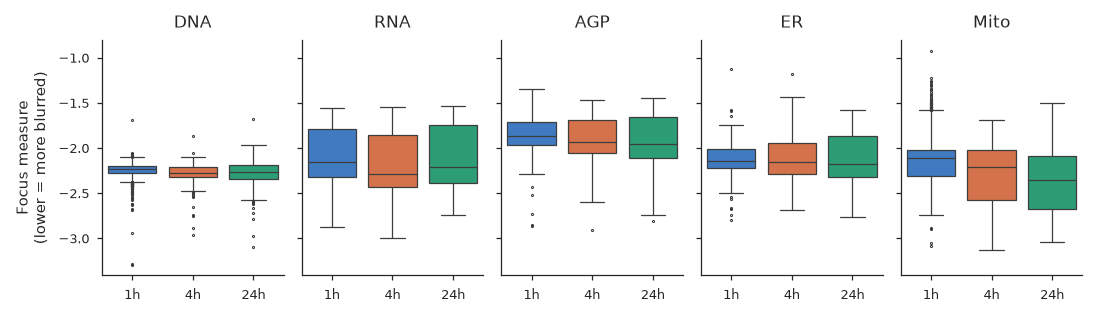

plate,cell_line,images,blurred,DNA,RNA,AGP,ER,Mito
str,str,u32,u32,u32,u32,u32,u32,u32
"""1h""","""CL1""",1710,17,15,4,5,2,0
"""4h""","""CL1""",1710,2,2,1,2,1,0
"""24h""","""CL1""",1707,0,0,0,0,0,0
"""1h""","""CL2""",1710,8,5,5,5,2,4
"""4h""","""CL2""",1710,10,8,6,4,3,3
"""24h""","""CL2""",1710,28,9,17,18,5,3


In [4]:
def robust_z(column, by):
    """Distance from the group median, in units of the group's spread (MAD)."""
    median = pl.col(column).median().over(by)
    mad = (pl.col(column) - median).abs().median().over(by) * 1.4826
    return (pl.col(column) - median) / mad


# one row per image: its quality measurements are the same for every cell in it
quality_columns = [f"Image_ImageQuality_{measure}_{ch}" for measure in ("PowerLogLogSlope", "MaxIntensity", "PercentMaximal") for ch in channels]
sites = (
    pl.concat(
        [
            pl.scan_parquet(plate_files[time])
            .select("Metadata_Well", "Metadata_Acquisition", *quality_columns)
            .unique("Metadata_Acquisition")
            .with_columns(pl.lit(time).alias("plate"))
            .collect()
            for time in plate_order
        ]
    )
    .join(wells.select("Metadata_Well", "cell_line"), on="Metadata_Well", how="left")
    # a fixed row order, so that the random examples below are the same in every run
    .sort("plate", "Metadata_Acquisition")
)
sites = sites.with_columns(
    *[(robust_z(f"Image_ImageQuality_PowerLogLogSlope_{ch}", ["plate", "cell_line"]) < blur_limit).alias(f"blurred_{ch}") for ch in channels]
)
focus = pl.concat(
    [sites.select("plate", pl.lit(ch).alias("channel"), pl.col(f"Image_ImageQuality_PowerLogLogSlope_{ch}").alias("focus")) for ch in channels]
)
fig, axes = plt.subplots(1, 5, figsize=(7.2, 2.0), sharey=True, layout="constrained")
for ax, ch in zip(axes, channels):
    sns.boxplot(
        data=focus.filter(pl.col("channel") == ch).to_pandas(), x="plate", y="focus", hue="plate",
        order=plate_order, palette=plate_colors, ax=ax, fliersize=0.5, linewidth=0.6, legend=False,
    )
    ax.set(title=ch, xlabel="")
axes[0].set_ylabel("Focus measure\n(lower = more blurred)")
plt.show()

# blurred images: in total, and per channel
in_time_order(
    sites.group_by("plate", "cell_line").agg(
        pl.len().alias("images"),
        pl.any_horizontal([f"blurred_{ch}" for ch in channels]).sum().alias("blurred"),
        *[pl.col(f"blurred_{ch}").sum().alias(ch) for ch in channels],
    )
)

**Result: 65 of 10,257 images are blurred (0–1.6% per plate and cell line).**

- Most blurred images are in CL2 at 24h (28) and CL1 at 1h (17), and most of them are in the DNA, RNA or AGP channel.
- Apart from these images, the focus is similar across plates.
- The examples in section 4 show that the focus measure also catches images with a large out-of-focus object or debris. A few flagged images look sharp at this zoom.

## 3. Are the images over-exposed?

A pixel at the camera's maximum cannot get any brighter, so real differences in brightness are lost. We call a channel **over-exposed** if more than 1% of its pixels are at the maximum.

In [5]:
# PercentMaximal counts pixels at the image's own maximum, so it only means saturation
# when that maximum is close to the top of the camera range
sites = sites.with_columns(
    *[
        ((pl.col(f"Image_ImageQuality_MaxIntensity_{ch}") >= 0.99) & (pl.col(f"Image_ImageQuality_PercentMaximal_{ch}") > saturation_limit)).alias(f"saturated_{ch}")
        for ch in channels
    ]
)
# over-exposed images: in total, and per channel
in_time_order(
    sites.group_by("plate", "cell_line").agg(
        pl.len().alias("images"),
        pl.any_horizontal([f"saturated_{ch}" for ch in channels]).sum().alias("over-exposed"),
        *[pl.col(f"saturated_{ch}").sum().alias(ch) for ch in channels],
    )
)

plate,cell_line,images,over-exposed,DNA,RNA,AGP,ER,Mito
str,str,u32,u32,u32,u32,u32,u32,u32
"""1h""","""CL1""",1710,9,7,2,0,0,0
"""4h""","""CL1""",1710,4,2,2,0,0,1
"""24h""","""CL1""",1707,109,1,1,0,0,108
"""1h""","""CL2""",1710,0,0,0,0,0,0
"""4h""","""CL2""",1710,6,2,4,0,0,2
"""24h""","""CL2""",1710,17,5,2,1,0,14


**Result: 145 images are over-exposed.**

- 108 of them are Mito images of CL1 at 24h (6.3% of those images), where dense clumps of cells are very bright. All other groups have at most 17.
- Over-exposure in one channel mostly affects the brightness features of that channel. `Metadata_image_qc_reason` names the channel, so a later analysis can choose to keep these images.

## 4. Image QC result

An image **fails** if any channel is blurred or over-exposed. All cells in that image then get `fail` in `Metadata_image_qc`, and `Metadata_image_qc_reason` gives the reason.

The examples show the middle of each image. Red marks pixels at the camera's maximum. The two tables after the examples count the failed images and cells.

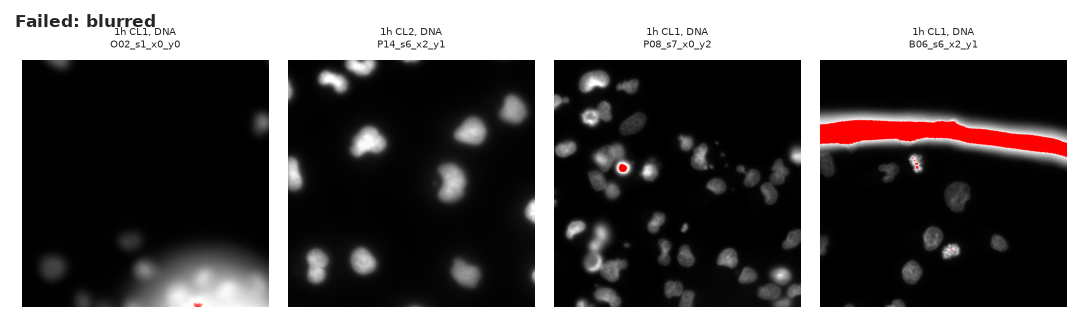

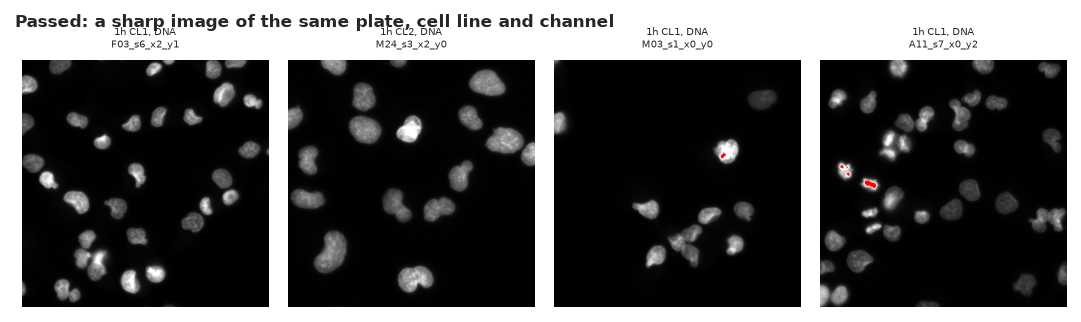

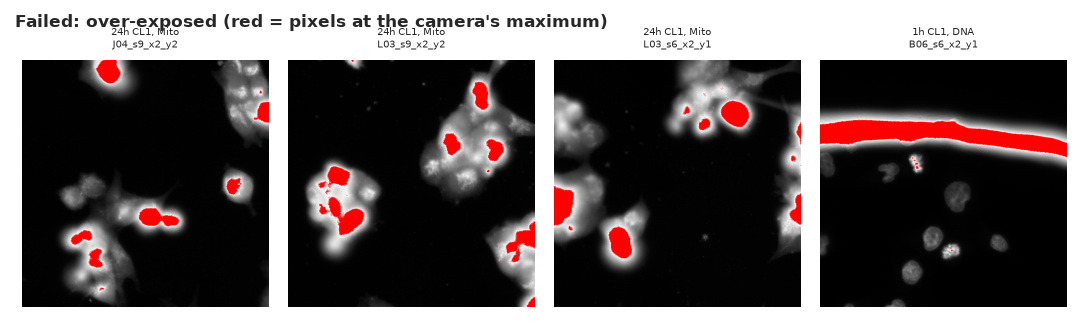

In [6]:
def channel_list(prefix):
    """The channels where a flag is set, for example "DNA, Mito"; empty if none."""
    return pl.concat_str([pl.when(pl.col(f"{prefix}_{ch}")).then(pl.lit(ch)) for ch in channels], separator=", ", ignore_nulls=True)


sites = sites.with_columns(channel_list("blurred").alias("blurred_channels"), channel_list("saturated").alias("saturated_channels"))
sites = sites.with_columns(
    pl.concat_str(
        [
            pl.when(pl.col("blurred_channels") != "").then(pl.format("blurred ({})", "blurred_channels")),
            pl.when(pl.col("saturated_channels") != "").then(pl.format("over-exposed ({})", "saturated_channels")),
        ],
        separator="; ",
        ignore_nulls=True,
    ).alias("image_qc_reason")
).with_columns(pl.when(pl.col("image_qc_reason") == "").then(pl.lit("pass")).otherwise(pl.lit("fail")).alias("image_qc"))

cells = cells.join(sites.select("plate", "Metadata_Acquisition", "image_qc", "image_qc_reason"), on=["plate", "Metadata_Acquisition"], how="left")
if cells["image_qc"].null_count():
    raise ValueError("Some cells have no image QC result")

failure_type = (
    pl.when((pl.col("blurred_channels") != "") & (pl.col("saturated_channels") != ""))
    .then(pl.lit("blurred and over-exposed"))
    .when(pl.col("blurred_channels") != "")
    .then(pl.lit("blurred"))
    .otherwise(pl.lit("over-exposed"))
)


def read_tiff(path):
    """Read one TIFF file as an array."""
    return np.array(Image.open(path)).astype(float)


def show_images(title, examples, crop=600):
    """Show the middle of each example image; red marks pixels at the camera's maximum."""
    if examples.is_empty():
        print(f"{title}: no images")
        return
    fig, axes = plt.subplots(1, len(examples), figsize=(1.8 * len(examples), 2.1))
    for ax, example in zip(np.atleast_1d(axes), examples.iter_rows(named=True)):
        channel = example["channel"]
        image = read_tiff(images_dir / plate_names[example["plate"]] / f"{example['Metadata_Acquisition']}_Fluorescence_{channel_wavelength[channel]}_nm_Ex.tiff")
        y, x = (np.array(image.shape) - crop) // 2
        window = image[y : y + crop, x : x + crop]
        low, high = np.percentile(window, [1, 99.8])
        rgb = np.dstack([np.clip((window - low) / (high - low), 0, 1)] * 3)
        rgb[window >= 0.99 * 65535] = (1, 0, 0)
        ax.imshow(rgb)
        ax.axis("off")
        ax.set_title(f"{example['plate']} {example['cell_line']}, {channel}\n{example['Metadata_Acquisition']}", fontsize=5)
    fig.suptitle(title, x=0.01, ha="left", fontsize=8, fontweight="bold")
    plt.tight_layout()
    plt.show()


blurred = sites.filter(pl.col("blurred_channels") != "").sample(n=min(4, (sites["blurred_channels"] != "").sum()), seed=seed)
blurred = blurred.with_columns(pl.col("blurred_channels").str.split(", ").list.first().alias("channel"))
sharp = pl.concat(
    [
        sites.filter((pl.col("image_qc") == "pass") & (pl.col("plate") == row["plate"]) & (pl.col("cell_line") == row["cell_line"]))
        .sample(n=1, seed=seed + i)
        .with_columns(pl.lit(row["channel"]).alias("channel"))
        for i, row in enumerate(blurred.iter_rows(named=True))
    ]
)
over_exposed = sites.filter(pl.col("saturated_channels") != "").sample(n=min(4, (sites["saturated_channels"] != "").sum()), seed=seed)
over_exposed = over_exposed.with_columns(pl.col("saturated_channels").str.split(", ").list.first().alias("channel"))

show_images("Failed: blurred", blurred)
show_images("Passed: a sharp image of the same plate, cell line and channel", sharp)
show_images("Failed: over-exposed (red = pixels at the camera's maximum)", over_exposed)

In [7]:
# images and cells that fail image QC, per plate and cell line
in_time_order(
    cells.group_by("plate", "cell_line").agg(
        pl.col("Metadata_Acquisition").n_unique().alias("images"),
        pl.col("Metadata_Acquisition").filter(pl.col("image_qc") == "fail").n_unique().alias("failed images"),
        pl.len().alias("cells"),
        (pl.col("image_qc") == "fail").sum().alias("cells in failed images"),
        (100 * (pl.col("image_qc") == "fail").mean()).round(2).alias("% of cells"),
    )
)

plate,cell_line,images,failed images,cells,cells in failed images,% of cells
str,str,u32,u32,u32,u32,f64
"""1h""","""CL1""",1710,20,437353,4980,1.14
"""4h""","""CL1""",1710,6,445903,1658,0.37
"""24h""","""CL1""",1707,109,359875,19255,5.35
"""1h""","""CL2""",1710,8,348879,1570,0.45
"""4h""","""CL2""",1710,11,411720,2494,0.61
"""24h""","""CL2""",1710,39,643991,9042,1.4


In [8]:
# why the images fail
sites.filter(pl.col("image_qc") == "fail").group_by(failure_type.alias("failed images")).len().sort("len", descending=True)

failed images,len
str,u32
"""over-exposed""",128
"""blurred""",48
"""blurred and over-exposed""",17


**Result: 193 images fail (128 over-exposed, 48 blurred, 17 both). They hold 38,999 cells, 1.5% of all cells.**

- CL1 at 24h loses the most: 5.4% of its cells, nearly all because of over-exposed Mito images. All other groups lose 0.4–1.4%.
- **Blurred examples:** a large out-of-focus object, softly blurred nuclei, and a bright streak of debris across the image. One example looks sharp at this zoom, so the blur check also removes a few good images.
- **Over-exposed examples:** bright clumps of cells with large saturated areas in the Mito channel, and the debris streak in the DNA channel.

# Part B: profile QC

## 5. Run coSMicQC

coSMicQC flags a cell when a measurement lies far from the average of its plate and cell line. We use the rules from Figure 2 of the coSMicQC paper ([bioRxiv](https://www.biorxiv.org/content/10.1101/2025.10.14.682427v2)):

| Condition | Looks for | Flag if |
|---|---|---|
| 1. Under-segmented nuclei | Two or more nuclei in one outline | DNA off-center (z > 0.05) **and** high nucleus DNA (z > 1.5) |
| 2. Poorly segmented nuclei | Debris, or a nucleus cut in pieces | Rough nucleus outline (solidity z < -1.6) |
| 3. Under-segmented cells | One cell outline that holds other nuclei | High DNA in the whole cell (z > 0.5) |

- We compute the z-scores per plate and cell line, because the two lines have different normal shapes. Section 11 compares this choice with z-scores over the whole plate.
- Panel A of Figure 2 prints 1.15 and -1.16. The paper text and the authors' code use 1.5 and -1.6, so we use those.
- coSMicQC checks the outlines of all cells, including the cells in failed images.

The code below marks each cell with one True/False column per condition. Sections 6–11 test whether these marks are right, before section 12 sets the final rule.

In [9]:
def flag_cells(table, rules, group_columns):
    """Run coSMicQC on each group of cells, and add one True/False column per condition."""
    results = []
    for _, group in table.group_by(group_columns, maintain_order=True):
        labeled = analyze.label_outliers(df=group.select(measurements).to_pandas(), feature_thresholds=rules)
        labeled = pd.DataFrame(labeled)
        if len(labeled) != group.height:
            raise ValueError("coSMicQC returned a different number of cells")
        marks = {name: labeled[f"Metadata_cqc_{name}_is_outlier"].to_numpy() for name in rules}
        results.append(group.select("row_id").with_columns(pl.Series(name, values) for name, values in marks.items()))
    marked = table.join(pl.concat(results), on="row_id", how="left")
    return marked.with_columns(pl.any_horizontal(list(rules)).alias("failed_qc"))


cells = flag_cells(cells, conditions, ["plate", "cell_line"])
print(cells.select(*condition_names, "failed_qc").mean().with_columns(pl.all() * 100).to_dicts()[0])

{'under_segmented_nuclei': 5.603422717121631, 'poorly_segmented_nuclei': 8.58156882843774, 'under_segmented_cells': 18.866036111810875, 'failed_qc': 23.140466839217577}


## 6. How many cells fail?

In the coSMicQC paper, 4–38% of cells failed. We also expect more failures in crowded wells.

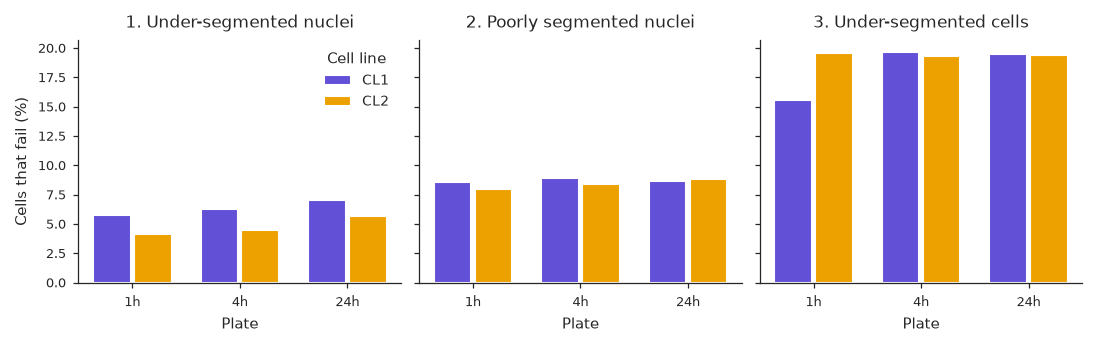

plate,cell_line,cells,under_segmented_nuclei,poorly_segmented_nuclei,under_segmented_cells,failed_qc
str,str,u32,f64,f64,f64,f64
"""1h""","""CL1""",437353,5.8,8.6,15.6,19.7
"""4h""","""CL1""",445903,6.3,8.9,19.7,23.4
"""24h""","""CL1""",359875,7.0,8.7,19.5,23.1
"""1h""","""CL2""",348879,4.1,8.0,19.6,25.0
"""4h""","""CL2""",411720,4.5,8.4,19.3,25.3
"""24h""","""CL2""",643991,5.7,8.8,19.4,23.0


In [10]:
rates = in_time_order(
    cells.group_by("plate", "cell_line").agg(pl.len().alias("cells"), *[(pl.col(name).mean() * 100).round(1) for name in [*condition_names, "failed_qc"]])
)
overlap = (
    cells.with_columns(pl.sum_horizontal(condition_names).alias("n_failed"))
    .group_by("cell_line", "n_failed")
    .len()
    .with_columns((100 * pl.col("len") / pl.col("len").sum().over("cell_line")).round(1).alias("percent"))
    .sort("cell_line", "n_failed")
)

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.2), sharey=True, layout="constrained")
width = 0.38
for ax, name in zip(axes, condition_names):
    for offset, line in zip((-width / 2, width / 2), line_order):
        values = [rates.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))[name].item() for time in plate_order]
        ax.bar(np.arange(3) + offset, values, width * 0.92, color=line_colors[line], label=line)
    ax.set(title=condition_titles[name], xticks=range(3), xticklabels=plate_order, xlabel="Plate")
axes[0].set_ylabel("Cells that fail (%)")
axes[0].legend(title="Cell line")
plt.show()
rates

In [11]:
# how many of the 3 conditions each cell fails
overlap

cell_line,n_failed,len,percent
str,u32,u32,f64
"""CL1""",0,969958,78.0
"""CL1""",1,162972,13.1
"""CL1""",2,80467,6.5
"""CL1""",3,29734,2.4
"""CL2""",0,1065068,75.8
"""CL2""",1,246176,17.5
"""CL2""",2,64223,4.6
"""CL2""",3,29123,2.1


**Result: in the expected range.** 19.7–25.3% of cells fail. Condition 3 flags the most cells (15.6–19.7%). Condition 1 flags 4.1–7.0%, and condition 2 flags 8.0–8.9%. Crowded wells do not fail more.

## 7. Where do the DNA limits sit?

Conditions 1 and 3 flag high DNA. A healthy G2 cell has twice the DNA of a G1 cell. So a limit below 2 times the G1 peak flags healthy cells.

**Pass if:** the condition 1 limit lies above 2 times the G1 peak.

In [12]:
def first_peak(values):
    """Position of the tallest peak of the DNA signal, on a log2 scale (the same as notebook 01)."""
    counts, bin_edges = np.histogram(values, bins=120, range=(5, 12))
    smooth = ndi.gaussian_filter1d(counts.astype(float), 1.5)
    return bin_edges[np.argmax(smooth)] + (bin_edges[1] - bin_edges[0]) / 2


rows = []
for time in plate_order:
    for line in line_order:
        group = cells.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))
        peak = 2 ** first_peak(np.log2(group[nucleus_dna].to_numpy()))
        cell_peak = 2 ** first_peak(np.log2(group[cell_dna].to_numpy()))
        rows.append(
            {
                "plate": time,
                "cell_line": line,
                "first_peak": peak,
                "first_peak_cell": cell_peak,
                "average_dna": group[nucleus_dna].mean(),
                "average_vs_first_peak": group[nucleus_dna].mean() / peak,
                "condition_1_limit_vs_first_peak": (group[nucleus_dna].mean() + 1.5 * group[nucleus_dna].std(ddof=0)) / peak,
                "condition_3_limit_vs_first_peak": (group[cell_dna].mean() + 0.5 * group[cell_dna].std(ddof=0)) / cell_peak,
            }
        )
peaks = pl.DataFrame(rows)

cells = cells.join(peaks.select("plate", "cell_line", "first_peak"), on=["plate", "cell_line"]).with_columns(
    (pl.col(nucleus_dna) / pl.col("first_peak")).alias("dna_vs_first_peak")
)

# what each DNA peak most likely holds, at its position on the log2 scale
dna_peaks = {0: "G1", 1: "G2", np.log2(3): "3×", 2: "4×"}


def label_dna_peaks(ax):
    """Mark the expected DNA peaks, and the region of pieces and debris, at the top of a panel."""
    ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
    for position, label in dna_peaks.items():
        ax.axvline(position, color=guide_color, ls=":", lw=0.6)
        ax.text(position, 0.98, label, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=5.5, color=guide_color)
    ax.text(-1.8, 0.98, "pieces,\ndebris", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=5.5, color=guide_color)


bins = np.arange(-3, 3.2, 0.05)
peaks.select("plate", "cell_line", pl.col("^.*vs_first_peak$").round(2))

plate,cell_line,average_vs_first_peak,condition_1_limit_vs_first_peak,condition_3_limit_vs_first_peak
str,str,f64,f64,f64
"""1h""","""CL1""",1.84,3.66,2.33
"""1h""","""CL2""",1.43,2.54,1.88
"""4h""","""CL1""",2.08,4.21,2.57
"""4h""","""CL2""",1.48,2.66,1.88
"""24h""","""CL1""",2.4,5.22,3.25
"""24h""","""CL2""",1.44,2.69,1.95


**Result: PASS for condition 1, but not for condition 3 in CL2.**

- The condition 1 limit lies at 2.5–2.7 times the G1 peak in CL2, and at 3.7–5.2 times in CL1.
- The condition 3 limit lies at 1.88–1.95 times the G1 peak in CL2, just below the G2 peak. In CL1, it lies at 2.3–3.3 times.
- The CL1 limits are high because merged nuclei raise the CL1 average.

## 8. Which DNA groups fail?

A good rule flags the objects outside the two peaks, and keeps the peaks.

| DNA group (× G1 peak) | Likely content |
|---|---|
| Too little (below 0.7) | Pieces of nuclei, debris |
| First peak (0.8–1.25) | Healthy G1 cells |
| Second peak (1.6–2.5) | Healthy G2 cells |
| Too much (above 2.8) | Merged nuclei |

In [13]:
cells = cells.with_columns(
    pl.when(pl.col("dna_vs_first_peak") < 0.7)
    .then(pl.lit("1 too little"))
    .when(pl.col("dna_vs_first_peak").is_between(0.8, 1.25))
    .then(pl.lit("2 first peak"))
    .when(pl.col("dna_vs_first_peak").is_between(1.6, 2.5))
    .then(pl.lit("3 second peak"))
    .when(pl.col("dna_vs_first_peak") > 2.8)
    .then(pl.lit("4 too much"))
    .otherwise(pl.lit("between groups"))
    .alias("dna_group")
)
dna_groups = in_time_order(
    cells.filter(pl.col("dna_group") != "between groups")
    .group_by("cell_line", "plate", "dna_group")
    .agg((100 * pl.col("failed_qc").mean()).round(1).alias("failed"))
    .pivot(on="dna_group", index=["cell_line", "plate"], values="failed", sort_columns=True)
)
# share of cells that fail QC (%), per DNA group
dna_groups

cell_line,plate,1 too little,2 first peak,3 second peak,4 too much
str,str,f64,f64,f64,f64
"""CL1""","""1h""",30.0,2.7,9.9,100.0
"""CL1""","""4h""",20.7,2.7,6.9,97.3
"""CL1""","""24h""",9.0,1.9,5.7,73.5
"""CL2""","""1h""",12.8,7.4,54.0,100.0
"""CL2""","""4h""",10.0,9.2,45.8,100.0
"""CL2""","""24h""",16.3,3.3,52.4,100.0


In [14]:
shares = in_time_order(
    cells.group_by("cell_line", "plate", "dna_group")
    .len()
    .with_columns((100 * pl.col("len") / pl.col("len").sum().over("cell_line", "plate")).round(1).alias("percent"))
    .pivot(on="dna_group", index=["cell_line", "plate"], values="percent", sort_columns=True)
)
# share of all cells in each DNA group (%)
shares

cell_line,plate,1 too little,2 first peak,3 second peak,4 too much,between groups
str,str,f64,f64,f64,f64,f64
"""CL1""","""1h""",0.2,45.8,32.0,13.7,8.3
"""CL1""","""4h""",0.3,37.8,33.2,19.7,9.0
"""CL1""","""24h""",0.4,37.7,30.3,27.5,4.2
"""CL2""","""1h""",2.0,54.4,26.5,4.5,12.6
"""CL2""","""4h""",3.1,50.0,28.4,5.4,13.1
"""CL2""","""24h""",2.1,58.5,23.1,6.4,9.9


In [15]:
# which condition fails the cells of the second peak?
second_peak = in_time_order(
    cells.filter(pl.col("dna_group") == "3 second peak")
    .group_by("cell_line", "plate")
    .agg(pl.len().alias("cells"), *[(pl.col(name).mean() * 100).round(1) for name in condition_names])
)
# cells in the second peak: share that fail each condition (%)
second_peak

cell_line,plate,cells,under_segmented_nuclei,poorly_segmented_nuclei,under_segmented_cells
str,str,u32,f64,f64,f64
"""CL1""","""1h""",139808,0.0,8.0,2.2
"""CL1""","""4h""",148164,0.0,6.4,0.6
"""CL1""","""24h""",109030,0.0,4.2,1.6
"""CL2""","""1h""",92373,0.0,6.2,51.6
"""CL2""","""4h""",117113,0.0,5.4,43.3
"""CL2""","""24h""",148666,0.0,12.2,47.6


In [16]:
# which condition fails the objects with too much DNA (likely merged nuclei)?
too_much = in_time_order(
    cells.filter(pl.col("dna_group") == "4 too much")
    .group_by("cell_line", "plate")
    .agg(pl.len().alias("cells"), *[(pl.col(name).mean() * 100).round(1) for name in condition_names])
)
# cells with too much DNA: share that fail each condition (%)
too_much

cell_line,plate,cells,under_segmented_nuclei,poorly_segmented_nuclei,under_segmented_cells
str,str,u32,f64,f64,f64
"""CL1""","""1h""",59872,42.3,30.3,100.0
"""CL1""","""4h""",87895,31.9,26.2,96.9
"""CL1""","""24h""",98905,25.6,23.9,68.1
"""CL2""","""1h""",15771,76.7,28.4,100.0
"""CL2""","""4h""",22169,76.4,24.1,100.0
"""CL2""","""24h""",41360,83.2,46.0,100.0


**Result: PASS for CL1, FAIL for CL2 G2 cells.**

- Too much DNA: 13.7–27.5% of CL1 objects and 4.5–6.4% of CL2 objects. 73.5–100% of them fail.
- First peak: 1.9–9.2% fail, as hoped.
- Second peak: 5.7–9.9% fail in CL1, but 45.8–54.0% fail in CL2.
- **Condition 3 causes the CL2 G2 failures.** It fails 43–52% of CL2 G2 cells, and only 0.6–2.2% in CL1.
- But condition 3 also finds most merged nuclei in CL1 (68–100%). Condition 1 finds only 26–42% of them.

## 9. Do flagged cells look wrong?

The figure shows eight random control cells per group. Yellow = nucleus outline, magenta = cell outline.

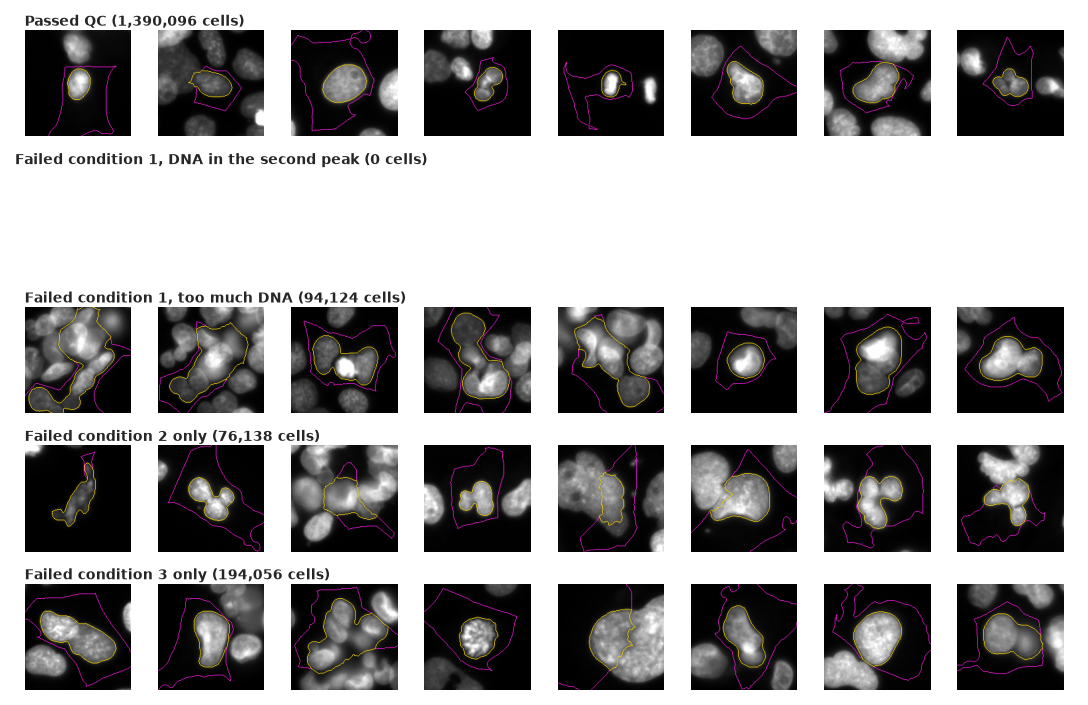

In [17]:
def plate_masks(time):
    """Folder with the masks of one plate."""
    plate = plate_names[time]
    run_dir = pathlib.Path((cellprofiler_dir / plate / "DONE").read_text().strip())
    return run_dir / "masks" / plate


def edge_of(mask):
    """Pixels on the edge of one object."""
    return mask & ~ndi.binary_erosion(mask, iterations=1, border_value=1)


def show_examples(groups, n_columns=8, half=80):
    """Draw random cells from each named group: one row per group."""
    fig, axes = plt.subplots(len(groups), n_columns, figsize=(7.2, 1.0 * len(groups)))
    for row, (title, selection) in enumerate(groups.items()):
        # a fixed row order, so that the random examples are the same in every run
        picks = selection.sort("plate", "Metadata_Acquisition", "Metadata_ObjectNumber").sample(n=min(n_columns, selection.height), seed=seed)
        for column in range(n_columns):
            ax = axes[row, column]
            ax.axis("off")
            if column == 0:
                ax.text(0, 1.04, f"{title} ({selection.height:,} cells)", transform=ax.transAxes, fontsize=6.5, fontweight="bold")
            if column >= picks.height:
                continue
            cell = picks.row(column, named=True)
            time, site, number = cell["plate"], cell["Metadata_Acquisition"], cell["Metadata_ObjectNumber"]
            dna = read_tiff(images_dir / plate_names[time] / f"{site}_Fluorescence_405_nm_Ex.tiff")
            nuclei = read_tiff(plate_masks(time) / f"{site}_Nuclei.tiff")
            whole_cells = read_tiff(plate_masks(time) / f"{site}_Cells.tiff")
            y = int(np.clip(cell["Nuclei_Location_Center_Y"], half, dna.shape[0] - half))
            x = int(np.clip(cell["Nuclei_Location_Center_X"], half, dna.shape[1] - half))
            window = (slice(y - half, y + half), slice(x - half, x + half))
            low, high = np.percentile(dna[window], [1, 99.8])
            gray = np.clip((dna[window] - low) / (high - low), 0, 1)
            rgb = np.dstack([gray] * 3)
            rgb[edge_of(whole_cells[window] == number)] = (1, 0.1, 0.9)
            rgb[edge_of(nuclei[window] == number)] = (1, 0.85, 0)
            ax.imshow(rgb)
    # fixed spacing: tight_layout shrinks the images to fit the long row titles
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.02, top=0.9, wspace=0.06, hspace=0.3)
    plt.show()


control = cells.filter(pl.col("well_type") == "control")
only_one = pl.sum_horizontal(condition_names) == 1
show_examples(
    {
        "Passed QC": control.filter(~pl.col("failed_qc")),
        "Failed condition 1, DNA in the second peak": control.filter(pl.col("under_segmented_nuclei") & (pl.col("dna_group") == "3 second peak")),
        "Failed condition 1, too much DNA": control.filter(pl.col("under_segmented_nuclei") & (pl.col("dna_group") == "4 too much")),
        "Failed condition 2 only": control.filter(pl.col("poorly_segmented_nuclei") & only_one),
        "Failed condition 3 only": control.filter(pl.col("under_segmented_cells") & only_one),
    }
)

**Result: conditions 1 and 2 look right. Condition 3 does not.**

- **Condition 1, too much DNA:** clumps of 2–4 nuclei in one outline. Correct.
- **Condition 2 only:** mostly two touching nuclei in one outline. Correct.
- **Condition 3 only:** mostly single normal nuclei, so false alarms. The sample mixes both lines, and condition 3 works well in CL1 (section 8).
- The row for condition 1 with G2 DNA is empty, because the condition 1 limit lies above the G2 peak.

## 10. Do the DNA peaks survive QC?

**Pass if:** removing the failed cells removes the objects outside the peaks, and keeps both peaks.

The table counts the objects with too little DNA and the objects in the second peak, before and after QC with all 3 conditions. Section 12 draws the DNA curves, next to the final rule.

In [18]:
in_time_order(cells.group_by("cell_line", "plate").agg(
    (100 * (pl.col("dna_vs_first_peak") < 0.7).mean()).round(1).alias("too_little_dna_before"),
    (100 * (pl.col("dna_vs_first_peak") < 0.7).filter(~pl.col("failed_qc")).mean()).round(1).alias("too_little_dna_after"),
    (100 * pl.col("dna_vs_first_peak").is_between(1.6, 2.5).mean()).round(1).alias("second_peak_before"),
    (100 * pl.col("dna_vs_first_peak").is_between(1.6, 2.5).filter(~pl.col("failed_qc")).mean()).round(1).alias("second_peak_after"),
))

cell_line,plate,too_little_dna_before,too_little_dna_after,second_peak_before,second_peak_after
str,str,f64,f64,f64,f64
"""CL1""","""1h""",0.2,0.2,32.0,35.9
"""CL1""","""4h""",0.3,0.3,33.2,40.3
"""CL1""","""24h""",0.4,0.5,30.3,37.1
"""CL2""","""1h""",2.0,2.3,26.5,16.2
"""CL2""","""4h""",3.1,3.7,28.4,20.6
"""CL2""","""24h""",2.1,2.3,23.1,14.3


**Result: PASS for CL1, FAIL for CL2.**

- In CL1, the extra peaks at 3 and 4 DNA sets disappear, and the G1 and G2 peaks stay.
- In CL2, the upper half of the G2 peak disappears (from 23–28% to 14–21% of objects). This would bias any cell-cycle result.

## 11. Do our choices change the result?

We repeat the analysis with the panel A limits (1.15 and -1.16), and with z-scores over the whole plate.

In [19]:
versions = {
    "1.5 and -1.6, per cell line": None,
    "1.15 and -1.16, per cell line": flag_cells(cells.select(columns + ["row_id", "plate", "cell_line"]), conditions_panel_a, ["plate", "cell_line"]),
    "1.5 and -1.6, whole plate": flag_cells(cells.select(columns + ["row_id", "plate", "cell_line"]), conditions, ["plate"]),
}
extra = cells.select("row_id", "dna_group")
rows = []
for version, table in versions.items():
    table = cells if table is None else table.join(extra, on="row_id")
    summary = table.group_by("cell_line").agg(
        *[(pl.col(name).mean() * 100).round(1) for name in [*condition_names, "failed_qc"]],
        (100 * pl.col("failed_qc").filter(pl.col("dna_group") == "1 too little").mean()).round(1).alias("too_little_dna_failed"),
        (100 * pl.col("failed_qc").filter(pl.col("dna_group") == "3 second peak").mean()).round(1).alias("second_peak_failed"),
    )
    rows.append(summary.with_columns(pl.lit(version).alias("version")))
pl.concat(rows).select("version", pl.exclude("version")).sort("cell_line", "version")

version,cell_line,under_segmented_nuclei,poorly_segmented_nuclei,under_segmented_cells,failed_qc,too_little_dna_failed,second_peak_failed
str,str,f64,f64,f64,f64,f64,f64
"""1.15 and -1.16, per cell line""","""CL1""",8.2,13.2,18.2,24.5,24.6,11.7
"""1.5 and -1.6, per cell line""","""CL1""",6.3,8.7,18.2,22.0,18.7,7.6
"""1.5 and -1.6, whole plate""","""CL1""",6.5,9.9,16.5,21.3,19.8,7.9
"""1.15 and -1.16, per cell line""","""CL2""",5.8,13.0,19.5,27.3,19.6,52.9
"""1.5 and -1.6, per cell line""","""CL2""",5.0,8.5,19.5,24.2,13.2,50.7
"""1.5 and -1.6, whole plate""","""CL2""",4.5,7.6,23.3,27.5,11.8,63.9


**Result: no.** With all three choices, half or more of the CL2 G2 cells fail (51–64%). Under 12% of the CL1 G2 cells fail.

## 12. The profile QC rule

Sections 8–10 lead to one rule per cell line:

- **CL1 uses all 3 conditions.**
- **CL2 uses conditions 1 and 2**, because condition 3 flags healthy G2 cells in CL2.

A cell **fails** if it fails a condition of the rule of its cell line. It then gets `fail` in `Metadata_profile_qc`, and `Metadata_profile_qc_reason` gives the reason.

**Pass if:** the rule removes most objects with too much DNA, keeps the G2 peak in both cell lines, and fails treated cells at a rate close to DMSO.

**Reading the DNA plot:**

- Grey: all objects.
- Dashed red: the objects that pass all 3 conditions (section 10).
- Solid: the objects that pass the rule of the cell line. In CL1, the rule uses all 3 conditions, so the two lines are the same.
- G1 and G2 mark one and two DNA sets. 3× is most likely a G1 and a G2 nucleus merged into one outline. 4× is two G2 nuclei merged, or one polyploid nucleus.
- Objects below 0.7 times G1 are pieces of nuclei or debris.

After the DNA plot, a table compares the failure rate of each treatment with DMSO, and a figure shows example cells.

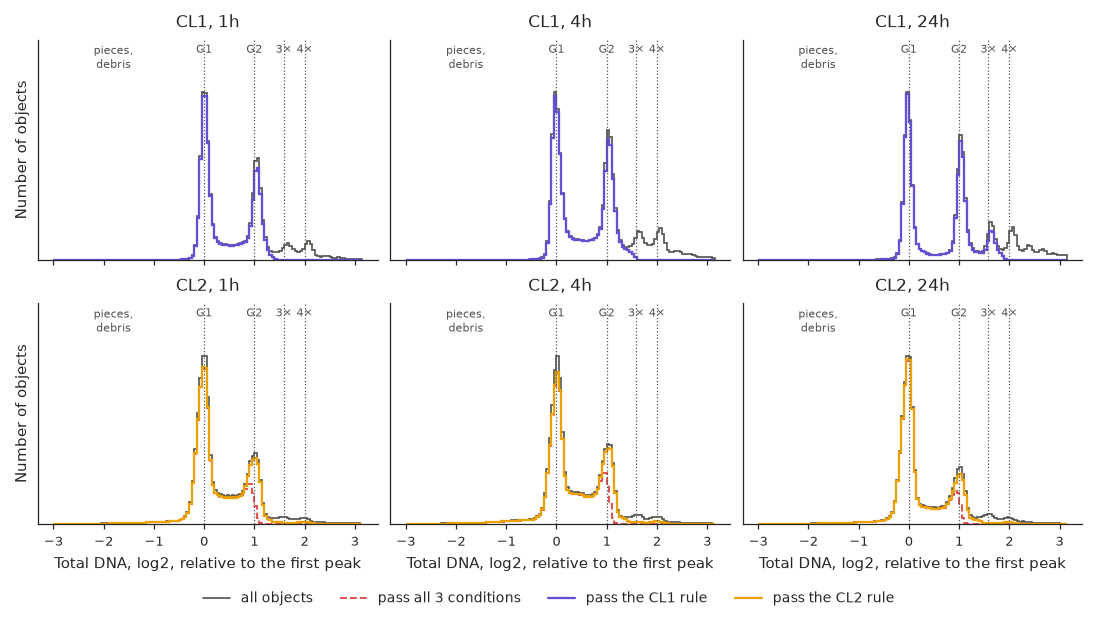

cell_line,plate,cells,removed,"removed, too little","removed, first peak","removed, second peak","removed, too much"
str,str,u32,f64,f64,f64,f64,f64
"""CL1""","""1h""",437353,19.7,30.0,2.7,9.9,100.0
"""CL1""","""4h""",445903,23.4,20.7,2.7,6.9,97.3
"""CL1""","""24h""",359875,23.1,9.0,1.9,5.7,73.5
"""CL2""","""1h""",348879,10.6,12.2,6.8,6.2,78.5
"""CL2""","""4h""",411720,11.6,9.3,8.5,5.4,77.9
"""CL2""","""24h""",643991,11.6,15.3,2.5,12.2,86.7


In [20]:
remove = pl.lit(False)
for line, names in rule_conditions.items():
    remove = pl.when(pl.col("cell_line") == line).then(pl.any_horizontal(names)).otherwise(remove)
cells = cells.with_columns(remove.alias("remove"))
cells = cells.with_columns(
    pl.when(pl.col("remove")).then(pl.lit("fail")).otherwise(pl.lit("pass")).alias("profile_qc"),
    pl.concat_str(
        [
            pl.when(pl.col(name) & pl.col("cell_line").is_in([line for line, names in rule_conditions.items() if name in names])).then(pl.lit(reason))
            for name, reason in condition_reasons.items()
        ],
        separator="; ",
        ignore_nulls=True,
    ).alias("profile_qc_reason"),
)

dna_group_names = ["1 too little", "2 first peak", "3 second peak", "4 too much"]
removed = in_time_order(
    cells.group_by("cell_line", "plate").agg(
        pl.len().alias("cells"),
        (100 * pl.col("remove").mean()).round(1).alias("removed"),
        *[(100 * pl.col("remove").filter(pl.col("dna_group") == group).mean()).round(1).alias(f"removed, {group[2:]}") for group in dna_group_names],
    )
)

# DNA content of all objects, of the objects that pass all 3 conditions (section 10), and of the objects that pass the rule
fig, axes = plt.subplots(2, 3, figsize=(7.2, 3.8), sharex=True, layout="constrained")
for row, line in enumerate(line_order):
    for column, time in enumerate(plate_order):
        ax = axes[row, column]
        group = cells.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))
        ax.hist(np.log2(group["dna_vs_first_peak"].to_numpy()), bins=bins, histtype="step", lw=0.8, color=guide_color)
        ax.hist(np.log2(group.filter(~pl.col("failed_qc"))["dna_vs_first_peak"].to_numpy()), bins=bins, histtype="step", lw=0.9, ls="--", color=limit_color)
        ax.hist(np.log2(group.filter(~pl.col("remove"))["dna_vs_first_peak"].to_numpy()), bins=bins, histtype="step", lw=1.1, color=line_colors[line])
        label_dna_peaks(ax)
        ax.set_title(f"{line}, {time}")
        ax.set_yticks([])
for ax in axes[1]:
    ax.set_xlabel("Total DNA, log2, relative to the first peak")
for ax in axes[:, 0]:
    ax.set_ylabel("Number of objects")
fig.legend(
    handles=[plt.Line2D([], [], color=guide_color, lw=0.8, label="all objects"),
             plt.Line2D([], [], color=limit_color, lw=0.9, ls="--", label="pass all 3 conditions"),
             *[plt.Line2D([], [], color=line_colors[l], lw=1.1, label=f"pass the {l} rule") for l in line_order]],
    loc="lower center", bbox_to_anchor=(0.5, -0.07), ncols=4,
)
plt.show()

# cells marked for removal (%)
removed

In [21]:
# compare each treatment with the control wells of the same plate and cell line
by_treatment = (
    cells.group_by("plate", "cell_line", "treatment", "well_type")
    .agg(pl.len().alias("cells"), (100 * pl.col("remove").mean()).alias("removed"))
    .filter(pl.col("cells") >= 500)
)
control_removed = by_treatment.filter(pl.col("well_type") == "control").select("plate", "cell_line", pl.col("removed").alias("control_removed"))
shift = (
    by_treatment.filter(pl.col("well_type") != "control")
    .join(control_removed, on=["plate", "cell_line"])
    .with_columns((pl.col("removed") - pl.col("control_removed")).alias("difference"))
)
print(f"difference from DMSO (points): median {shift['difference'].abs().median():.1f}, largest {shift['difference'].abs().max():.1f}")
shift.sort(pl.col("difference").abs(), descending=True).head(6).select("plate", "cell_line", "treatment", "cells", pl.col("removed").round(1), pl.col("control_removed").round(1), pl.col("difference").round(1))

difference from DMSO (points): median 0.6, largest 15.0


plate,cell_line,treatment,cells,removed,control_removed,difference
str,str,str,u32,f64,f64,f64
"""24h""","""CL2""","""CBK600005""",16914,25.9,10.9,15.0
"""24h""","""CL1""","""TGFb1""",9684,29.8,23.2,6.7
"""24h""","""CL1""","""CBK041498""",20582,18.9,23.2,-4.2
"""24h""","""CL2""","""TGFb1""",30169,14.8,10.9,3.9
"""24h""","""CL1""","""CBK200566""",15083,26.8,23.2,3.6
"""1h""","""CL1""","""CBK600005""",20022,22.3,19.5,2.8


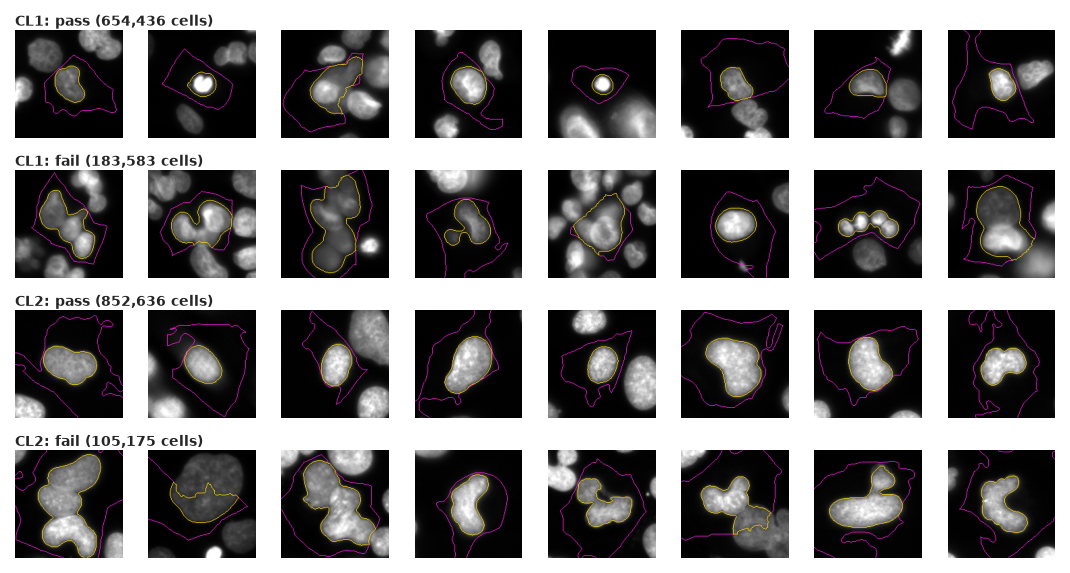

In [22]:
# example cells for each cell line: random control cells that pass or fail profile QC
control = cells.filter(pl.col("well_type") == "control")
show_examples({
    f"{line}: {qc}": control.filter((pl.col("cell_line") == line) & (pl.col("profile_qc") == qc))
    for line in line_order for qc in ["pass", "fail"]
})

**Result: PASS, with one treatment to check.**

- Profile QC fails 19.7–23.4% of CL1 cells and 10.6–11.6% of CL2 cells.
- **Merged nuclei fail:** 73.5–100% of CL1 objects and 77.9–86.7% of CL2 objects with too much DNA. At 24h, some CL1 objects at 3 DNA sets still pass.
- **The G2 peak stays in both lines.** The rule fails 5.4–12.2% of CL2 G2 cells, against 45.8–54.0% with all 3 conditions. The dashed red line loses the upper half of the CL2 G2 peak.
- **Example cells:** most failed cells hold two or more nuclei in one outline, or a nucleus with a ragged outline. Passed cells mostly have one nucleus with a clean outline.
- In CL1, a few failed cells look like single large nuclei. These are most likely two nuclei on top of each other, or a polyploid cell.
- Treated cells fail at a rate close to DMSO (median difference 0.6 points). The exception is **CBK600005 at 24h in CL2** (25.9% against 10.9%). Check these wells before filtering.

# Part C: the QC profile

## 13. Save the QC profile

We join the 3 plates into one table, `results/qc_Panc1_hPSC_sc-profiles.parquet`. It keeps every cell and every column of the profiles, and adds these columns at the front:

| Column | Content |
|---|---|
| `Metadata_cell_line`, `Metadata_time_point` | CL1 or CL2, and 1h, 4h or 24h |
| `Metadata_treatment`, `Metadata_well_type` | The compound or ligand (DMSO for controls), and compound, ligand or control |
| `Metadata_image_qc`, `Metadata_image_qc_reason` | `pass` or `fail`, and the reason (Part A) |
| `Metadata_profile_qc`, `Metadata_profile_qc_reason` | `pass` or `fail`, and the reason (Part B) |

**Pass if:** the QC profile has one row per cell of the 3 plates, and every cell has both QC results.

In [23]:
keys = ["Metadata_Plate", "Metadata_Acquisition", "Metadata_ObjectNumber"]
qc_columns = cells.select(
    *keys,
    pl.col("cell_line").alias("Metadata_cell_line"),
    pl.col("plate").alias("Metadata_time_point"),
    pl.col("treatment").alias("Metadata_treatment"),
    pl.col("well_type").alias("Metadata_well_type"),
    pl.col("image_qc").alias("Metadata_image_qc"),
    pl.col("image_qc_reason").alias("Metadata_image_qc_reason"),
    pl.col("profile_qc").alias("Metadata_profile_qc"),
    pl.col("profile_qc_reason").alias("Metadata_profile_qc_reason"),
)
if qc_columns.select(keys).is_duplicated().any():
    raise ValueError("Plate, image and object number must identify one cell")
new_columns = [name for name in qc_columns.columns if name not in keys]
profile_paths = "[" + ", ".join(f"'{plate_files[time]}'" for time in plate_order) + "]"

# write to a .partial file first, so an interrupted run never leaves a file that looks finished
partial = qc_profile_path.with_name(qc_profile_path.name + ".partial")
partial.unlink(missing_ok=True)
tmp_dir.mkdir(parents=True, exist_ok=True)
with duckdb.connect() as con:
    con.execute(f"SET memory_limit = '{duckdb_memory_limit}'")
    con.execute(f"SET threads = {n_threads}")
    con.execute(f"SET temp_directory = '{tmp_dir}'")
    con.execute("SET enable_progress_bar = false")
    con.register("qc", qc_columns.to_arrow())
    con.execute(f"""
        COPY (
            SELECT {", ".join(f"qc.{name}" for name in new_columns)}, profiles.*
            FROM read_parquet({profile_paths}) AS profiles
            JOIN qc USING ({", ".join(keys)})
        )
        TO '{partial}' (FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 10000)
    """)
partial.replace(qc_profile_path)
shutil.rmtree(tmp_dir, ignore_errors=True)

# check the file: one row per cell, all columns, and a QC result for every cell
schema = pl.scan_parquet(qc_profile_path).collect_schema()
n_columns = len(pl.scan_parquet(plate_files["1h"]).collect_schema())
qc_summary = (
    pl.scan_parquet(qc_profile_path)
    .group_by("Metadata_cell_line", "Metadata_time_point", "Metadata_image_qc", "Metadata_profile_qc")
    .len()
    .collect()
)
if qc_summary["len"].sum() != cells.height or len(schema) != n_columns + len(new_columns):
    raise ValueError("The QC profile does not have one row per cell and all columns")
if qc_summary.select(pl.col("Metadata_image_qc", "Metadata_profile_qc").null_count()).sum_horizontal().item():
    raise ValueError("Some cells have no QC result")

print(f"{qc_profile_path.name}: {qc_summary['len'].sum():,} cells, {len(schema):,} columns, {qc_profile_path.stat().st_size / 2**30:.1f} GiB")
(
    qc_summary.group_by("Metadata_cell_line", "Metadata_time_point")
    .agg(
        pl.col("len").sum().alias("cells"),
        (100 * pl.col("len").filter(pl.col("Metadata_image_qc") == "fail").sum() / pl.col("len").sum()).round(2).alias("% fail image QC"),
        (100 * pl.col("len").filter(pl.col("Metadata_profile_qc") == "fail").sum() / pl.col("len").sum()).round(1).alias("% fail profile QC"),
        (100 * pl.col("len").filter((pl.col("Metadata_image_qc") == "pass") & (pl.col("Metadata_profile_qc") == "pass")).sum() / pl.col("len").sum()).round(1).alias("% pass both"),
    )
    .with_columns(pl.col("Metadata_time_point").replace_strict({time: i for i, time in enumerate(plate_order)}, return_dtype=pl.Int64).alias("order"))
    .sort("Metadata_cell_line", "order")
    .drop("order")
)

qc_Panc1_hPSC_sc-profiles.parquet: 2,647,721 cells, 4,062 columns, 53.8 GiB


Metadata_cell_line,Metadata_time_point,cells,% fail image QC,% fail profile QC,% pass both
str,str,u32,f64,f64,f64
"""CL1""","""1h""",437353,1.14,19.7,79.5
"""CL1""","""4h""",445903,0.37,23.4,76.4
"""CL1""","""24h""",359875,5.35,23.1,73.1
"""CL2""","""1h""",348879,0.45,10.6,88.9
"""CL2""","""4h""",411720,0.61,11.6,87.9
"""CL2""","""24h""",643991,1.4,11.6,87.3


**Result: PASS.**

- The QC profile holds all 2,647,721 cells and 4,062 columns (53.8 GiB): the 4,054 columns of the profiles plus 8 new columns.
- Every cell has both QC results. 73.1–88.9% of cells pass both checks.

## Summary

- **Data:** 2,647,721 single cells from 3 plates (1h, 4h and 24h) and 2 cell lines.
- **Image QC:** an image fails if a channel is blurred (focus more than 5 MADs below its plate and cell line) or over-exposed (over 1% of pixels at the camera's maximum). 193 images fail, and they hold 1.5% of cells.
- **Profile QC:** a cell fails if coSMicQC finds a bad outline. CL1 uses all 3 conditions, and CL2 uses conditions 1 and 2. 10.6–23.4% of cells fail, mostly merged nuclei.
- **Output:** `results/qc_Panc1_hPSC_sc-profiles.parquet`, one table for all plates. Keep the cells where `Metadata_image_qc` and `Metadata_profile_qc` are both `pass` (73.1–88.9% of cells), then preprocess.
- **Caveats:**
  - The blur check removes a few sharp images.
  - The profile rule removes some single nuclei with a lot of DNA (stacked nuclei or polyploid cells).
  - The rule per cell line is our choice, not part of the coSMicQC paper.
- **Still open:** check the CBK600005 wells at 24h in CL2, where many cells fail profile QC.